# Week 1 - Chuẩn hóa và các kiểu dữ liệu

Tuần đầu tiên này sẽ là tuần khởi động, trong đó chúng ta sẽ tìm hiểu các công cụ thống kê cho các kiểu dữ liệu khác nhau.

Trước tiên, hãy import các thư viện cần thiết.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats

## Bài tập 1: Thống kê mẫu và chuẩn hóa

Cho $X$ và $Y$ là hai biến ngẫu nhiên, lần lượt biểu diễn age (tuổi) và weight (cân nặng).
Xét một mẫu ngẫu nhiên kích thước $n=20$ từ hai biến này.

In [2]:
X = np.array([69, 74, 68, 70, 72, 67, 66, 70, 76, 68, 72, 79, 74, 67, 66, 71, 74, 75, 75, 76])
Y = np.array([153, 175, 155, 135, 172, 150, 115, 137, 200, 130, 140, 265, 185, 112, 140, 150, 165, 185, 210, 220])

**a)** Tìm mean, median và mode của $X$.

In [3]:
mean = np.mean(X)
median = np.median(X)
mode = scipy.stats.mode(X)
print(mean)
print(median)
mode

71.45
71.5


ModeResult(mode=np.int64(74), count=np.int64(3))

**b)** Phương sai (variance) của $Y$ là bao nhiêu?

In [4]:
# Phương sai của Y: np.var mặc định chia cho n (phương sai tổng thể),
# ddof=1 chia cho n-1 (phương sai mẫu, ước lượng không chệch)
print("Var(Y) chia n     :", np.var(Y))
print("Var(Y) chia n - 1 :", np.var(Y, ddof=1))

Var(Y) chia n     : 1369.2099999999998
Var(Y) chia n - 1 : 1441.2736842105262


**c)** Xác suất để quan sát được một người có age từ 70 trở lên là bao nhiêu?

In [5]:
np.sum(X >= 70) / len(X)

np.float64(0.65)

**d)** Vẽ phân phối chuẩn (normal distribution) cho $X$.

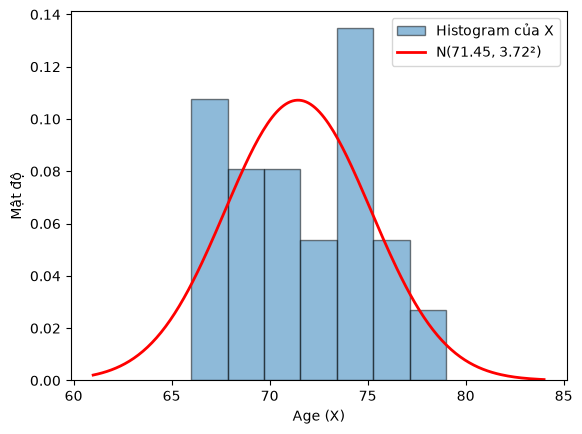

In [6]:
# Histogram (chuẩn hóa thành mật độ) + đường phân phối chuẩn N(mean, std) ước lượng từ mẫu
mu, sigma = X.mean(), X.std()
xs = np.linspace(X.min() - 5, X.max() + 5, 200)

plt.hist(X, bins=7, density=True, alpha=0.5, edgecolor='black', label='Histogram của X')
plt.plot(xs, scipy.stats.norm.pdf(xs, mu, sigma), 'r-', lw=2, label=f'N({mu:.2f}, {sigma:.2f}²)')
plt.xlabel('Age (X)')
plt.ylabel('Mật độ')
plt.legend()
plt.show()

**e)** Tìm trung bình 2 chiều $\hat \mu$ và ma trận hiệp phương sai (covariance matrix) $\widehat \Sigma$ cho hai biến này.

In [7]:
D = np.column_stack([X, Y])          # ma trận dữ liệu n x 2

mu_hat = D.mean(axis=0)
Sigma_hat = np.cov(D, rowvar=False)  # chia cho n-1; dùng bias=True nếu muốn chia cho n

print("Trung bình 2 chiều mu_hat =", mu_hat)
print("Ma trận hiệp phương sai Sigma_hat =")
print(Sigma_hat)
print("Hệ số tương quan X, Y =", round(np.corrcoef(X, Y)[0, 1], 4))

Trung bình 2 chiều mu_hat = [ 71.45 164.7 ]
Ma trận hiệp phương sai Sigma_hat =
[[  14.57631579  128.87894737]
 [ 128.87894737 1441.27368421]]
Hệ số tương quan X, Y = 0.8892


**f)** Chuẩn hóa dữ liệu bằng _range normalization_ về khoảng $[0, 1]$.

In [8]:
X1 = (X - X.min()) / (X.max() - X.min())
Y1 = (Y - Y.min()) / (Y.max() - Y.min())
print("X1: ",X1)
print("Y1: ",Y1)

X1:  [0.23076923 0.61538462 0.15384615 0.30769231 0.46153846 0.07692308
 0.         0.30769231 0.76923077 0.15384615 0.46153846 1.
 0.61538462 0.07692308 0.         0.38461538 0.61538462 0.69230769
 0.69230769 0.76923077]
Y1:  [0.26797386 0.41176471 0.28104575 0.1503268  0.39215686 0.24836601
 0.01960784 0.16339869 0.5751634  0.11764706 0.18300654 1.
 0.47712418 0.         0.18300654 0.24836601 0.34640523 0.47712418
 0.64052288 0.70588235]


**g)** Chuẩn hóa dữ liệu bằng _standard score normalization_ (Z-score normalization), sao cho dữ liệu có mean bằng 0 và standard deviation bằng 1.

In [9]:
X_mean = np.mean(X)
Y_mean = np.mean(Y)
X_var = np.sqrt(np.var(X))
Y_var = np.sqrt(np.var(Y))

X2 = (X - X_mean) / X_var
Y2 = (Y - Y_mean) / Y_var
print("X2: ",X2)
print("Y2: ",Y2)



X2:  [-0.65838571  0.6852586  -0.92711457 -0.38965685  0.14780087 -1.19584344
 -1.4645723  -0.38965685  1.22271632 -0.92711457  0.14780087  2.02890291
  0.6852586  -1.19584344 -1.4645723  -0.12092799  0.6852586   0.95398746
  0.95398746  1.22271632]
Y2:  [-0.31619197  0.27835703 -0.26214206 -0.80264114  0.19728217 -0.39726683
 -1.34314023 -0.74859124  0.95398089 -0.93776592 -0.66751637  2.71060292
  0.54860657 -1.42421509 -0.66751637 -0.39726683  0.00810749  0.54860657
  1.22423043  1.49447997]


## Bài tập 2: Tính robust (độ bền vững)

Xác định xem các phát biểu sau là đúng (True) hay sai (False) và giải thích tại sao.
- Mean thì robust đối với outliers.
- Median thì robust đối với outliers.
- Standard deviation thì robust đối với outliers.

**Trả lời Bài tập 2**

| Phát biểu | Đúng/Sai | Giải thích |
|---|---|---|
| Mean robust với outlier | **Sai** | Mean dùng mọi giá trị với trọng số như nhau; chỉ một outlier rất lớn cũng kéo mean lệch tùy ý (breakdown point = 0). |
| Median robust với outlier | **Đúng** | Median chỉ phụ thuộc vào thứ tự; phải thay gần 50% dữ liệu thì median mới bị kéo đi xa (breakdown point = 50%). |
| Standard deviation robust với outlier | **Sai** | Std dựa trên mean và **bình phương** độ lệch, nên outlier còn bị khuếch đại. Thước đo robust thay thế: IQR, MAD quanh median. |

In [10]:
# Minh họa: thêm một outlier vào X
X_out = np.append(X, 300)
print(f"{'':10s}{'mean':>10s}{'median':>10s}{'std':>10s}")
for name, v in [('X gốc', X), ('X + 300', X_out)]:
    print(f"{name:10s}{v.mean():10.2f}{np.median(v):10.2f}{v.std():10.2f}")

                mean    median       std
X gốc          71.45     71.50      3.72
X + 300        82.33     72.00     48.81


## Bài tập 4: Phân tích tính độc lập (Independence analysis)

Hãy giải thích ý tưởng của phân tích tính độc lập bằng contingency table; loại dữ liệu nào mà phương pháp này đặc biệt phù hợp (kiểu dữ liệu, số lượng biến)?

**Trả lời Bài tập 4**

- **Ý tưởng:** lập bảng chéo (contingency table) đếm số lần xuất hiện của từng cặp giá trị $(x_i, y_j)$. Nếu hai biến **độc lập** thì tần số kỳ vọng của mỗi ô là $E_{ij} = \dfrac{n_{i\cdot} \, n_{\cdot j}}{n}$ (tích hai tần số biên chia cho $n$). So sánh tần số quan sát $O_{ij}$ với $E_{ij}$ bằng thống kê
  $$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$
  với bậc tự do $q = (r-1)(c-1)$. $\chi^2$ càng lớn thì càng có cơ sở bác bỏ giả thuyết độc lập.
- **Kiểu dữ liệu phù hợp:** thuộc tính **phân loại (categorical)**, hoặc thuộc tính số đã được **rời rạc hóa** thành các bin (như Bài 5).
- **Số lượng biến:** thường là **2 biến** (bảng 2 chiều). Có thể mở rộng cho nhiều biến (bảng nhiều chiều như Bài 9) nhưng số ô tăng theo cấp số nhân, cần nhiều dữ liệu để mỗi ô có tần số kỳ vọng đủ lớn (thường ≥ 5).

## Bài tập 5: Contingency table và thống kê $\chi^2$

Tổng bình phương của các biến ngẫu nhiên thuộc phân phối chuẩn

Trong bảng dưới đây, giả sử rằng $X_1$ được rời rạc hóa thành ba bins như sau: $[-2, -0.5]$, $[-0.5, 0.5]$, và $[0.5, 2]$.

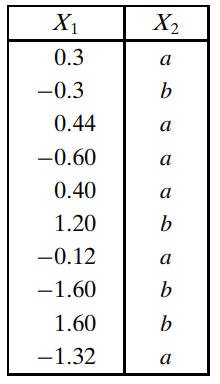

Trả lời các câu hỏi sau:

**a)** Xây dựng (contingency table) giữa thuộc tính $X_1$ (đã rời rạc hóa) và $X_2$. Bao gồm các tần số biên (marginal counts).  
**b)** Tính thống kê $\chi^2$ giữa hai thuộc tính này.  
**c)** Xác định xem chúng có phụ thuộc hay không ở mức ý nghĩa 5% (p-value). Sử dụng các giá trị tới hạn $\chi^2$ từ Bảng 3.10.

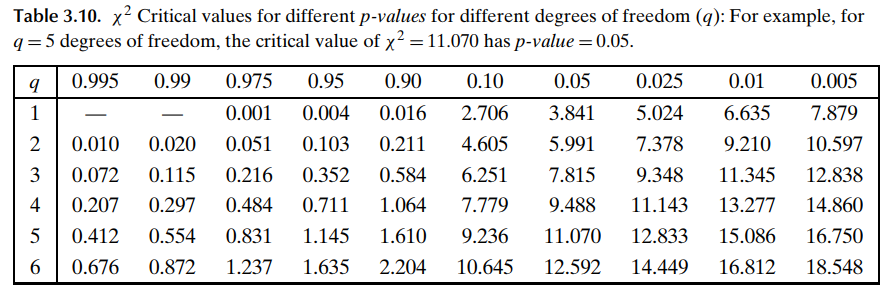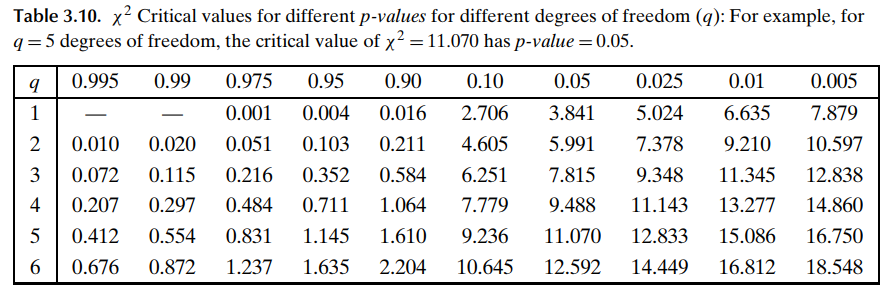




In [11]:
X1 = np.array([0.3, -0.3, 0.44, -0.60, 0.40, 1.20, -0.12, -1.60, 1.60, -1.32])
X2 = np.array(['a', 'b', 'a', 'a', 'a', 'b', 'a', 'b', 'b', 'a'])

# a) Rời rạc hóa X1 thành 3 bin [-2, -0.5], (-0.5, 0.5], (0.5, 2]
X1_bin = pd.cut(X1, bins=[-2, -0.5, 0.5, 2], labels=['[-2, -0.5]', '(-0.5, 0.5]', '(0.5, 2]'])
table = pd.crosstab(X1_bin, X2, rownames=['X1'], colnames=['X2'])
display(pd.crosstab(X1_bin, X2, rownames=['X1'], colnames=['X2'], margins=True, margins_name='Tổng'))

# b) Thống kê chi^2 (truyền bảng KHÔNG có hàng/cột tổng)
chi2, p_value, dof, expected = scipy.stats.chi2_contingency(table, correction=False)
print("Tần số kỳ vọng E_ij:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns))
print(f"chi2 = {chi2:.4f}, bậc tự do q = {dof}")

# c) So với giá trị tới hạn ở mức ý nghĩa 5% (Bảng 3.10: q = 2 -> 5.991)
critical = scipy.stats.chi2.ppf(0.95, df=dof)
print(f"Giá trị tới hạn (p = 0.05, q = {dof}) = {critical:.3f}, p-value = {p_value:.4f}")
print("=> Bác bỏ H0: X1 và X2 phụ thuộc" if chi2 > critical else "=> Không đủ cơ sở bác bỏ H0: X1 và X2 độc lập")

X2,a,b,Tổng
X1,,,
"[-2, -0.5]",2,1,3
"(-0.5, 0.5]",4,1,5
"(0.5, 2]",0,2,2
Tổng,6,4,10


Tần số kỳ vọng E_ij:


X2,a,b
X1,,
"[-2, -0.5]",1.8,1.2
"(-0.5, 0.5]",3.0,2.0
"(0.5, 2]",1.2,0.8


chi2 = 3.8889, bậc tự do q = 2
Giá trị tới hạn (p = 0.05, q = 2) = 5.991, p-value = 0.1431
=> Không đủ cơ sở bác bỏ H0: X1 và X2 độc lập


**Nhận xét Bài tập 5:** bảng có 3 hàng × 2 cột nên $q = (3-1)(2-1) = 2$, giá trị tới hạn ở mức 5% là $5.991$. $\chi^2 \approx 3.889 < 5.991$ nên **không bác bỏ** $H_0$: $X_1$ (đã rời rạc hóa) và $X_2$ **độc lập**.

Lưu ý: phải truyền vào `chi2_contingency` bảng **không có** hàng/cột tổng (`margins`), và lập bảng trên các **bin** chứ không phải trên giá trị gốc của $X_1$. Với chỉ 10 mẫu, nhiều ô có tần số kỳ vọng < 5 nên kiểm định $\chi^2$ ở đây chỉ mang tính minh họa.

## Bài tập 6: Làm việc với Metrics (Độ đo khoảng cách)

Xét tình huống sau:

Chúng ta biết một số khoảng cách giữa các điểm dữ liệu: $d(p_1,p_2)=1$, $d(p_1,p_3)=2$, $d(p_3, p_4)=1$.
Chúng ta cũng biết rằng $d$ là một độ đo.

1. Chúng ta biết gì về các khoảng cách còn lại?
2. Chúng ta có cần tính thêm các khoảng cách khác nếu muốn tìm hai điểm giống $p_1$ nhất không?
3. $p_4$ có thể gần $p_2$ hơn $p_3$ gần $p_2$ không?

**Trả lời Bài tập 6**

$d$ là metric nên thỏa: $d(x,y) \ge 0$, $d(x,y) = 0 \iff x = y$, đối xứng $d(x,y) = d(y,x)$ và **bất đẳng thức tam giác** $d(x,z) \le d(x,y) + d(y,z)$. Hệ quả: $|d(x,y) - d(y,z)| \le d(x,z)$.

1. **Các khoảng cách còn lại:**
   - $d(p_2,p_3)$: $|d(p_1,p_3) - d(p_1,p_2)| \le d(p_2,p_3) \le d(p_1,p_2) + d(p_1,p_3)$ ⇒ $1 \le d(p_2,p_3) \le 3$.
   - $d(p_1,p_4)$: $|d(p_1,p_3) - d(p_3,p_4)| \le d(p_1,p_4) \le d(p_1,p_3) + d(p_3,p_4)$ ⇒ $1 \le d(p_1,p_4) \le 3$.
   - $d(p_2,p_4)$: cận trên theo đường $p_2 \to p_1 \to p_3 \to p_4$ là $1 + 2 + 1 = 4$; cận dưới chỉ biết $> 0$ (vì $p_2 \ne p_4$) ⇒ $0 < d(p_2,p_4) \le 4$.
2. **Tìm hai điểm giống $p_1$ nhất:** $p_2$ chắc chắn gần nhất vì $d(p_1,p_2) = 1$, còn $d(p_1,p_3) = 2$ và $d(p_1,p_4) \ge 1$. Nhưng điểm thứ hai có thể là $p_3$ hoặc $p_4$ vì $d(p_1,p_4)$ có thể nằm bất kỳ đâu trong $[1, 3]$, nhỏ hơn hoặc lớn hơn 2. ⇒ **Có**, phải tính thêm $d(p_1,p_4)$.
3. **$p_4$ có thể gần $p_2$ hơn $p_3$ không? Có.** Bất đẳng thức tam giác chỉ ràng buộc $|d(p_2,p_3) - d(p_2,p_4)| \le d(p_3,p_4) = 1$, nên $d(p_2,p_4) < d(p_2,p_3)$ hoàn toàn có thể xảy ra. Ví dụ trong mặt phẳng với khoảng cách Euclid: $p_1 = (0,0)$, $p_2 = (1,0)$, $p_3 = (2,0)$, $p_4 = (1.2, 0.6)$ (kiểm chứng ở cell dưới).

In [12]:
# Kiểm chứng câu 3 bằng một ví dụ cụ thể với khoảng cách Euclid (là một metric)
p1, p2, p3 = np.array([0.0, 0.0]), np.array([1.0, 0.0]), np.array([2.0, 0.0])
p4 = np.array([1.2, 0.6])
d = lambda a, b: np.linalg.norm(a - b)

print(f"d(p1,p2) = {d(p1, p2):.3f}  (đề: 1)")
print(f"d(p1,p3) = {d(p1, p3):.3f}  (đề: 2)")
print(f"d(p3,p4) = {d(p3, p4):.3f}  (đề: 1)")
print(f"d(p2,p4) = {d(p2, p4):.3f}  <  d(p2,p3) = {d(p2, p3):.3f}")

d(p1,p2) = 1.000  (đề: 1)
d(p1,p3) = 2.000  (đề: 2)
d(p3,p4) = 1.000  (đề: 1)
d(p2,p4) = 0.632  <  d(p2,p3) = 1.000


# Bài tập thêm

## Bài tập 7: Mean absolute deviation (Độ lệch tuyệt đối trung bình)

Định nghĩa một độ đo độ lệch gọi là _mean absolute deviation_ cho biến ngẫu nhiên $X$ như sau:

$$
\frac{1}{n} \sum_{i=1}^n |x_i - \mu|
$$

Độ đo này có robust không? Tại sao hoặc tại sao không?

In [13]:
def mad_mean(v):
    return np.mean(np.abs(v - np.mean(v)))

def mad_median(v):
    return np.median(np.abs(v - np.median(v)))

print(f"{'':10s}{'std':>10s}{'MAD (mean)':>12s}{'MAD (median)':>14s}")
for name, v in [('X gốc', X), ('X + 300', np.append(X, 300))]:
    print(f"{name:10s}{v.std():10.2f}{mad_mean(v):12.2f}{mad_median(v):14.2f}")

                 std  MAD (mean)  MAD (median)
X gốc           3.72        3.25          3.50
X + 300        48.81       20.73          3.00


**Trả lời Bài tập 7:** mean absolute deviation **không robust**.

- Nó **ít nhạy** với outlier hơn std vì dùng $|x_i - \mu|$ (tăng tuyến tính) thay vì bình phương.
- Nhưng nó vẫn dựa trên **mean $\mu$** và cộng mọi độ lệch với trọng số như nhau, nên một outlier đủ lớn vẫn kéo giá trị tăng tùy ý (breakdown point = 0), như bảng trên cho thấy.
- Phiên bản robust là **median absolute deviation**: $\text{median}(|x_i - \text{median}(X)|)$, gần như không đổi khi thêm outlier.

## Bài tập 8: Correlation (Hệ số tương quan)

Xét bảng dưới đây. Giả sử rằng cả hai thuộc tính $X$ và $Y$ đều là numeric, và
bảng này biểu diễn toàn bộ population. Nếu chúng ta biết rằng correlation giữa $X$
và $Y$ bằng 0, chúng ta có thể suy ra điều gì về các giá trị của $Y$?

|$X$ | $Y$ |
|:---:|:---:|
|$1$|$a$|
|$0$|$b$|
|$1$|$c$|
|$0$|$a$|
|$0$|$c$|

**Trả lời Bài tập 8**

$\rho_{XY} = 0 \iff \text{cov}(X, Y) = \frac{1}{n}\sum_i (x_i - \mu_X)(y_i - \mu_Y) = 0$.

Với $\mu_X = \frac{2}{5} = 0.4$, các độ lệch $x_i - \mu_X$ lần lượt là $0.6, -0.4, 0.6, -0.4, -0.4$ (tổng bằng 0, nên số hạng chứa $\mu_Y$ triệt tiêu):

$$0.6a - 0.4b + 0.6c - 0.4a - 0.4c = 0.2a - 0.4b + 0.2c = 0 \;\Rightarrow\; \boxed{b = \frac{a + c}{2}}$$

Nghĩa là $b$ phải là **trung bình cộng** của $a$ và $c$: trung bình của $Y$ khi $X = 0$ (các giá trị $b, a, c$) bằng trung bình khi $X = 1$ (các giá trị $a, c$). Ngoài ra $Y$ không được là hằng số ($a, b, c$ không đồng thời bằng nhau), nếu không $\rho$ không xác định.

In [14]:
# Kiểm chứng với a, c tùy ý và b = (a + c) / 2
Xc = np.array([1, 0, 1, 0, 0])
for a, c in [(1, 5), (-2, 10), (3.5, 0.5)]:
    b = (a + c) / 2
    Yc = np.array([a, b, c, a, c])
    print(f"a={a}, b={b}, c={c} -> corr = {np.corrcoef(Xc, Yc)[0, 1]:.2e}")

a=1, b=3.0, c=5 -> corr = 0.00e+00
a=-2, b=4.0, c=10 -> corr = 1.69e-17
a=3.5, b=2.0, c=0.5 -> corr = -1.69e-17


## Bài tập 9: 3-way contingency table

Xét bảng trên cho các thuộc tính $X$, $Y$, $Z$ được biểu diễn trong bảng dưới đây.
Tính chỉ số $\chi^2$ cho correlation giữa $Y$ và $Z$. Chúng có phụ thuộc hay độc lập ở mức độ tin cậy 95% không? Xem Bảng 3.10 ở trên để tra giá trị $\chi^2$.

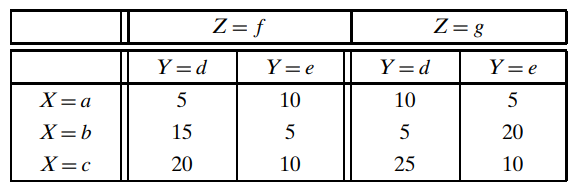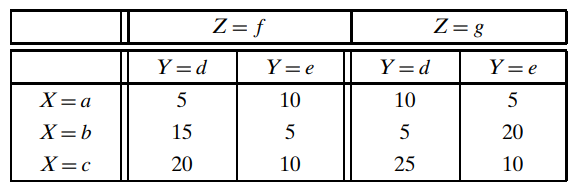

In [15]:
# Bảng 3 chiều: số đếm theo (X, Y, Z)
counts = pd.DataFrame(
    {('f', 'd'): [5, 15, 20], ('f', 'e'): [10, 5, 10],
     ('g', 'd'): [10, 5, 25], ('g', 'e'): [5, 20, 10]},
    index=pd.Index(['a', 'b', 'c'], name='X'))
counts.columns.names = ['Z', 'Y']
display(counts)

# Cộng dồn theo X để được bảng 2 chiều Y x Z
yz = counts.sum(axis=0).unstack('Z')
display(yz.assign(Tổng=yz.sum(axis=1)))

chi2, p_value, dof, expected = scipy.stats.chi2_contingency(yz, correction=False)
critical = scipy.stats.chi2.ppf(0.95, df=dof)
print("Tần số kỳ vọng:")
display(pd.DataFrame(expected, index=yz.index, columns=yz.columns).round(3))
print(f"chi2 = {chi2:.4f}, q = {dof}, giá trị tới hạn (p = 0.05) = {critical:.3f}, p-value = {p_value:.4f}")
print("=> Y và Z phụ thuộc" if chi2 > critical else "=> Không đủ cơ sở bác bỏ H0: Y và Z độc lập ở mức tin cậy 95%")

Z   f       g    
Y   d   e   d   e
X                
a   5  10  10   5
b  15   5   5  20
c  20  10  25  10

Z,f,g,Tổng
Y,,,
d,40,40,80
e,25,35,60


Tần số kỳ vọng:


Z,f,g
Y,,
d,37.143,42.857
e,27.857,32.143


chi2 = 0.9573, q = 1, giá trị tới hạn (p = 0.05) = 3.841, p-value = 0.3279
=> Không đủ cơ sở bác bỏ H0: Y và Z độc lập ở mức tin cậy 95%


**Nhận xét Bài tập 9:** cộng dồn theo $X$ được bảng $2 \times 2$ giữa $Y$ và $Z$, bậc tự do $q = (2-1)(2-1) = 1$, giá trị tới hạn ở $p = 0.05$ là $3.841$ (Bảng 3.10). $\chi^2 \approx 0.957 < 3.841$ nên **không bác bỏ** giả thuyết độc lập: $Y$ và $Z$ **độc lập** ở mức tin cậy 95%.

Lưu ý: `chi2_contingency` mặc định dùng hiệu chỉnh Yates khi $q = 1$; ở đây tắt (`correction=False`) để khớp công thức trong giáo trình.

## Bài tập 10: Mixed data (Dữ liệu hỗn hợp)

Xét dữ liệu "hỗn hợp" được cho trong bảng dưới đây. Ở đây $X_1$ là thuộc tính numeric và
$X_2$ là thuộc tính categorical. Giả sử domain của $X_2$ là $dom(X_2) = \{a, b\}$.
Trả lời các câu hỏi sau:
**a)** Mean vector của dataset này là gì?  
**b)** Covariance matrix là gì?

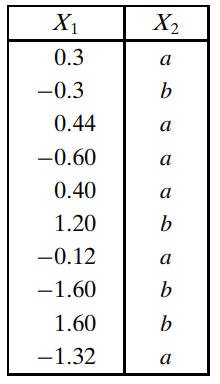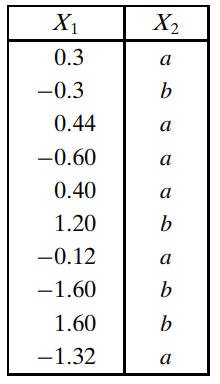

In [16]:
X1 = np.array([0.3, -0.3, 0.44, -0.60, 0.40, 1.20, -0.12, -1.60, 1.60, -1.32])
X2 = np.array(['a', 'b', 'a', 'a', 'a', 'b', 'a', 'b', 'b', 'a'])

# Thuộc tính categorical X2 được mã hóa thành vector chỉ thị (one-hot): a -> (1, 0), b -> (0, 1)
D = pd.DataFrame({'X1': X1, 'X2=a': (X2 == 'a').astype(int), 'X2=b': (X2 == 'b').astype(int)})
display(D.T)

# a) Mean vector
print("Mean vector:", D.mean().round(4).to_dict())

# b) Covariance matrix (chia cho n, như định nghĩa trong giáo trình)
print("Covariance matrix:")
display(D.cov(ddof=0).round(4))

,0,1,2,3,4,5,6,7,8,9
X1,0.3,-0.3,0.44,-0.6,0.4,1.2,-0.12,-1.6,1.6,-1.32
X2=a,1.0,0.0,1.00,1.0,1.0,0.0,1.00,0.0,0.0,1.00
X2=b,0.0,1.0,0.00,0.0,0.0,1.0,0.00,1.0,1.0,0.00


Mean vector: {'X1': 0.0, 'X2=a': 0.6, 'X2=b': 0.4}
Covariance matrix:


,X1,X2=a,X2=b
X1,0.921,-0.09,0.09
X2=a,-0.090,0.24,-0.24
X2=b,0.090,-0.24,0.24


**Nhận xét Bài tập 10:** thuộc tính categorical $X_2$ được biểu diễn bằng vector chỉ thị $(\mathbb{1}[X_2 = a], \mathbb{1}[X_2 = b])$; trung bình của mỗi chiều chính là **tần suất** của giá trị đó ($\hat p_a = 0.6$, $\hat p_b = 0.4$).

- Mean vector: $\hat\mu = (0,\; 0.6,\; 0.4)$ (tổng các giá trị $X_1$ bằng 0).
- Trên đường chéo phần categorical là $\hat p(1 - \hat p) = 0.24$; ô $(a, b)$ bằng $-\hat p_a \hat p_b = -0.24$ vì hai chỉ thị luôn có tổng bằng 1 (ma trận suy biến).
- Hiệp phương sai giữa $X_1$ và chỉ thị $a$ âm: các giá trị $X_1$ có $X_2 = a$ nhỏ hơn trung bình, nhóm $b$ chứa các giá trị lớn như 1.2, 1.6.